# 🏦 Loan Approval Prediction with SVM

Predict whether a loan application will be **approved (Y)** or **rejected (N)** from the applicant's profile: income, loan amount, credit history, education, employment and property area.

**Author:** Reda Akram · Computer Science (AI), University of Technology – Baghdad

## 1. Setup

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
sns.set_theme(style="whitegrid"); RANDOM_STATE = 42

## 2. Load the data

In [2]:
df = pd.read_csv("data/Loan_Approval.csv")
print(df.shape)
df.head()

(981, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
df.isnull().sum()

Loan_ID                0
Gender                24
Married                3
Dependents            25
Education              0
Self_Employed         55
ApplicantIncome        0
CoapplicantIncome      0
LoanAmount            27
Loan_Amount_Term      20
Credit_History        79
Property_Area          0
Loan_Status          367
dtype: int64

**Important:** 367 rows have no `Loan_Status` at all — they are unlabeled applications (originally a separate test file), so they cannot be used for training and are removed.

Every other missing value is in a *feature* (e.g. `Credit_History`, `LoanAmount`). Those rows are **kept** and filled by the imputers inside the pipeline. An earlier version of this notebook used `df.dropna()` on everything, which threw away usable applications.

In [4]:
df = df.dropna(subset=["Loan_Status"]).drop(columns="Loan_ID")
df["Loan_Status"] = df["Loan_Status"].map({"N": 0, "Y": 1})
print("Labeled rows:", len(df))
print(df["Loan_Status"].value_counts(normalize=True).round(3))

Labeled rows: 614
Loan_Status
1    0.687
0    0.313
Name: proportion, dtype: float64


## 3. EDA — what drives approval?

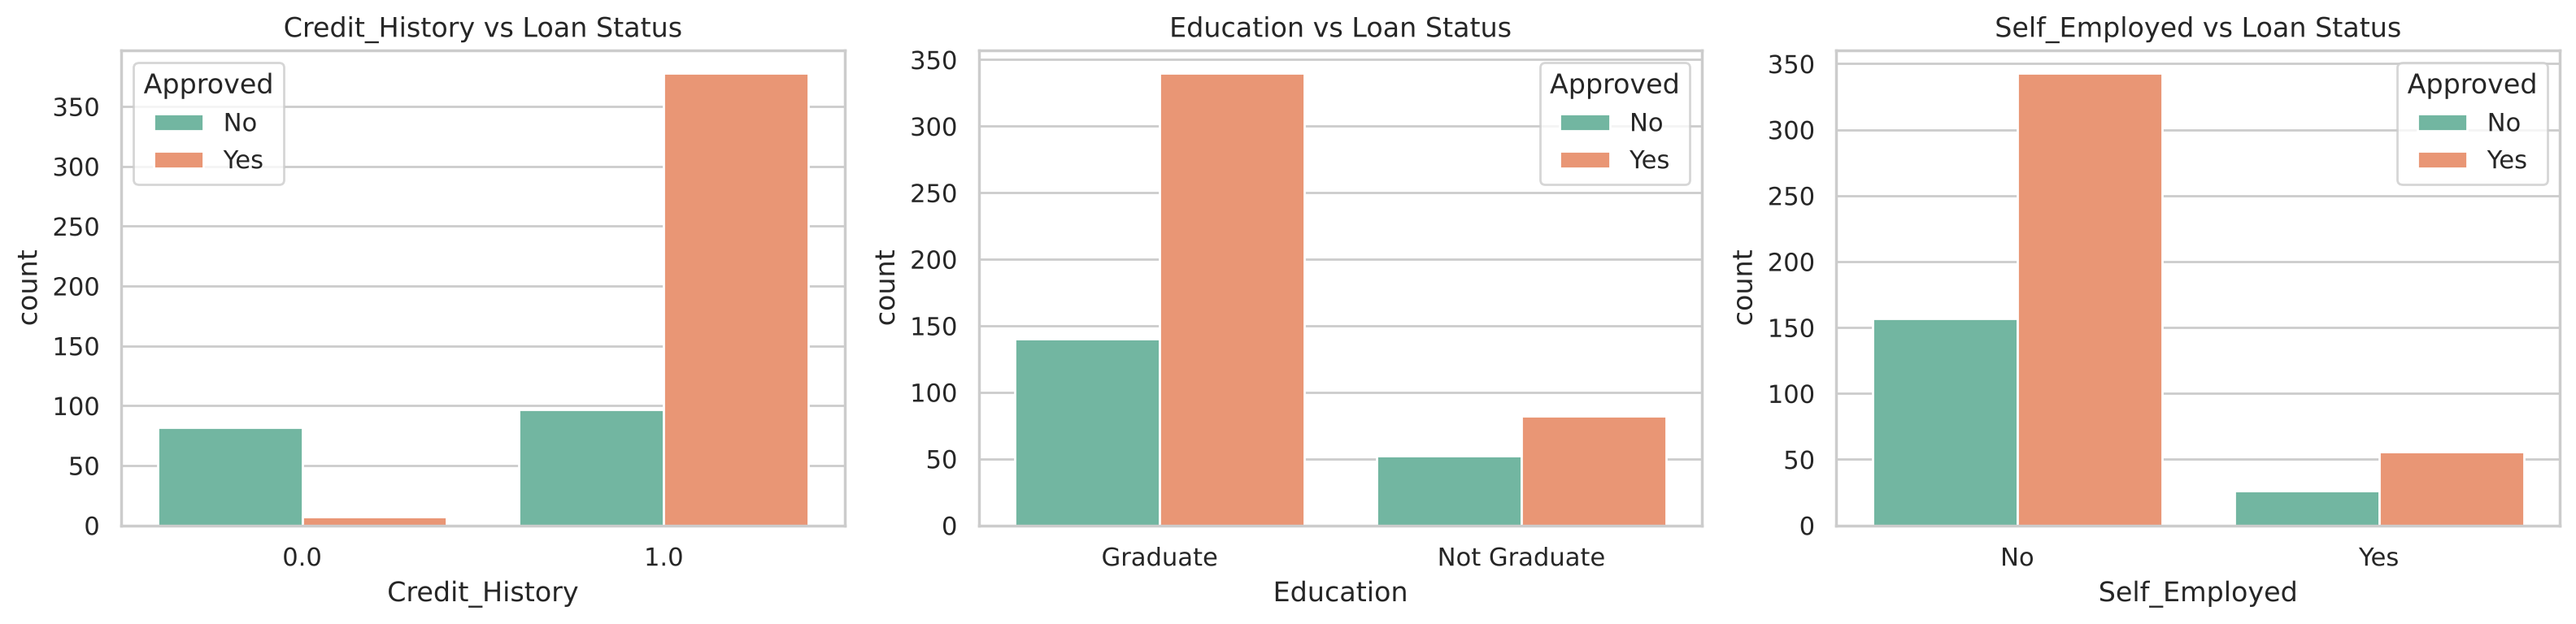

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Credit_History", "Education", "Self_Employed"]):
    sns.countplot(data=df, x=col, hue="Loan_Status", ax=ax, palette="Set2")
    ax.set_title(f"{col} vs Loan Status"); ax.legend(title="Approved", labels=["No", "Yes"])
plt.tight_layout(); plt.savefig("images/eda_categorical.png", dpi=120, bbox_inches="tight"); plt.show()

* **Credit history is by far the strongest signal**: applicants with a good history are approved most of the time, almost none without it are.
* Graduates and salaried (non self-employed) applicants get approved slightly more often — a steady income looks safer to the bank.

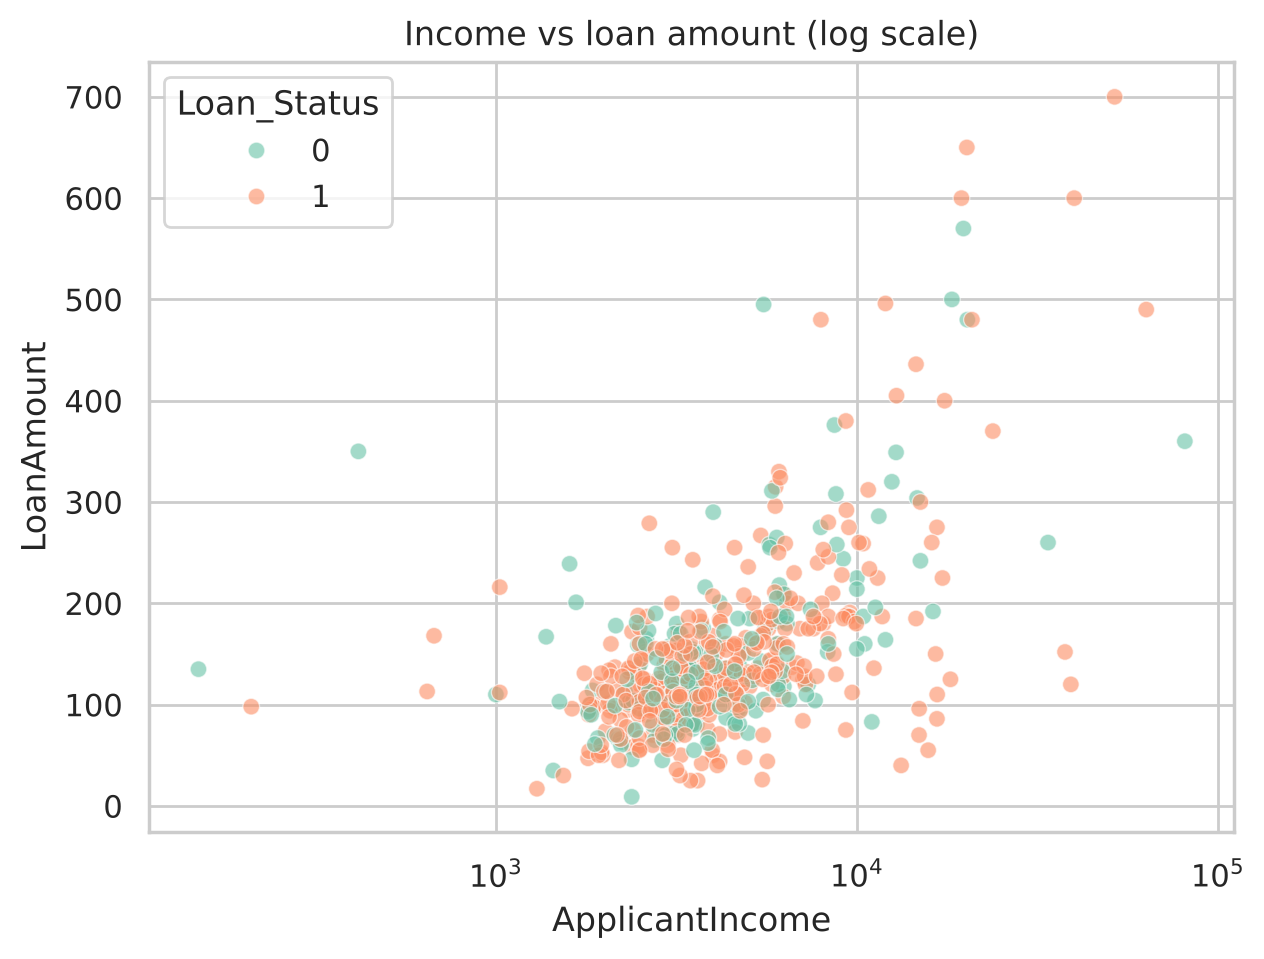

In [6]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="ApplicantIncome", y="LoanAmount", hue="Loan_Status", alpha=0.6, palette="Set2")
plt.xscale("log"); plt.title("Income vs loan amount (log scale)")
plt.savefig("images/income_vs_loan.png", dpi=120, bbox_inches="tight"); plt.show()

Income and loan amount alone **do not separate** approved from rejected applications — both groups overlap completely. Approval depends more on credit history than on salary.

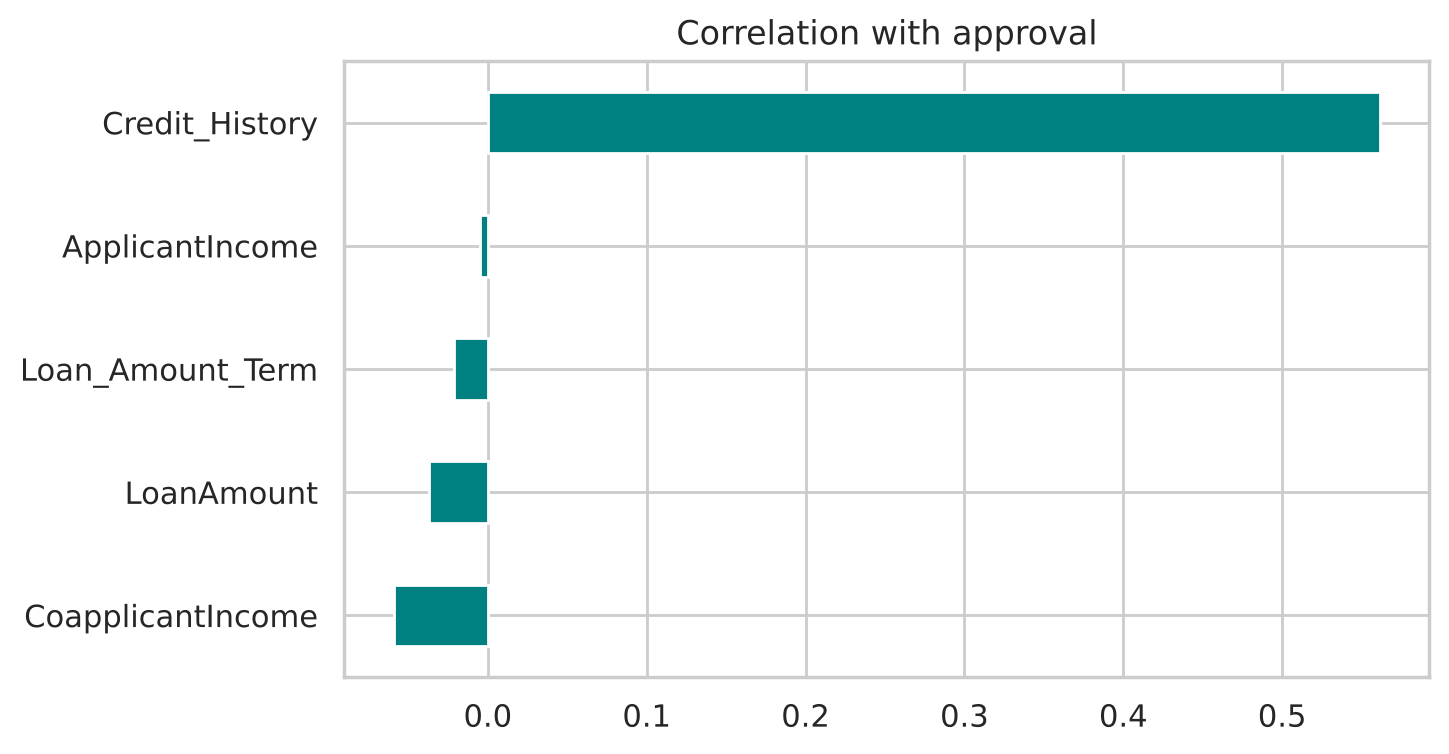

In [7]:
corr = df.corr(numeric_only=True)["Loan_Status"].drop("Loan_Status").sort_values()
corr.plot(kind="barh", color="teal", figsize=(7, 4)); plt.title("Correlation with approval")
plt.savefig("images/correlation.png", dpi=120, bbox_inches="tight"); plt.show()

## 4. Preprocessing pipeline

In [8]:
X = df.drop(columns="Loan_Status"); y = df["Loan_Status"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

num_features = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term", "Credit_History"]
cat_features = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Property_Area"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore"))]), cat_features),
])

## 5. Baseline
Any model must beat the trivial strategy of approving everyone.

In [9]:
base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Always-approve accuracy:", round(accuracy_score(y_test, base.predict(X_test)), 3))

Always-approve accuracy: 0.691


## 6. SVM + GridSearchCV over linear, RBF and polynomial kernels

In [10]:
pipe = Pipeline([("preprocessing", preprocessor), ("svm", SVC())])
param_grid = [
    {"svm__kernel": ["linear"], "svm__C": [0.1, 1, 10]},
    {"svm__kernel": ["rbf"], "svm__C": [0.1, 1, 10], "svm__gamma": ["scale", 0.1, 0.01]},
    {"svm__kernel": ["poly"], "svm__C": [0.1, 1, 10], "svm__degree": [2, 3, 4], "svm__coef0": [0, 1]},
]
grid = GridSearchCV(pipe, param_grid, cv=5, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)
print("Best params:", grid.best_params_)
print("Best CV F1 :", round(grid.best_score_, 3))

Best params: {'svm__C': 1, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
Best CV F1 : 0.87


## 7. Test-set evaluation

In [11]:
y_pred = grid.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("F1      :", round(f1_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred, target_names=["Rejected", "Approved"]))

Accuracy: 0.862
F1      : 0.908
              precision    recall  f1-score   support

    Rejected       0.96      0.58      0.72        38
    Approved       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



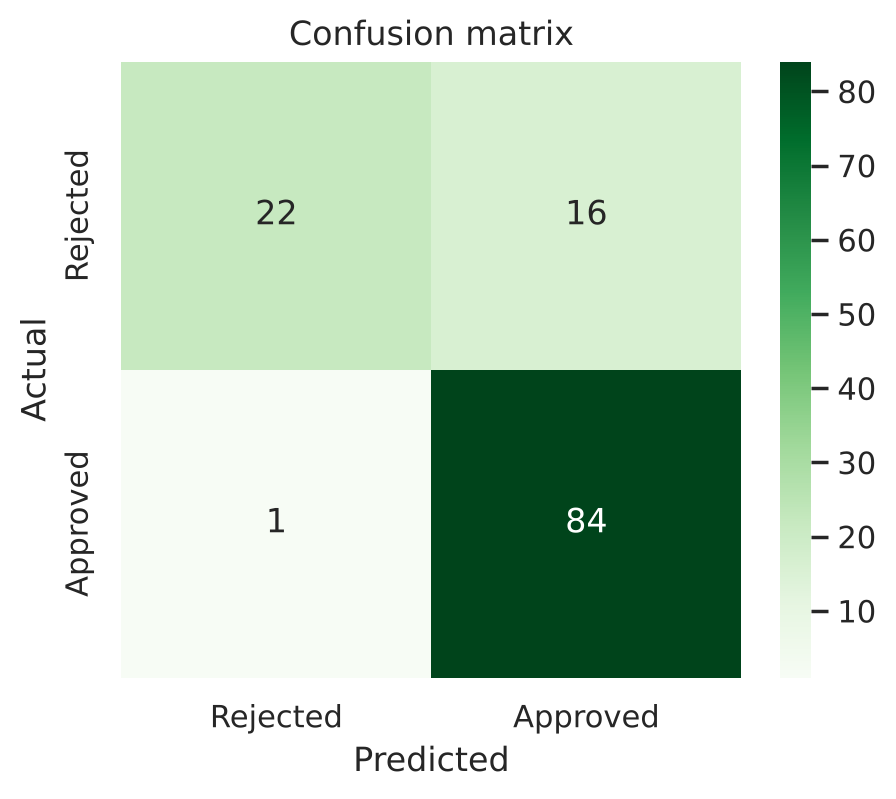

In [12]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=["Rejected", "Approved"], yticklabels=["Rejected", "Approved"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix")
plt.savefig("images/confusion_matrix.png", dpi=120, bbox_inches="tight"); plt.show()

## 8. Conclusion

* Keeping the rows with missing features (instead of `dropna()` on everything) raised test accuracy from **82.3% to 86.2%** and F1 from **0.889 to 0.908** — more data beat a fancier model.
* The grid search picked an **RBF kernel** (C=1, gamma=0.01): a smooth, low-complexity boundary, because the decision is mostly driven by one feature (credit history).
* The model beats the "approve everyone" baseline mainly by catching applicants with a bad credit history.
* Weak spot: some rejected applicants with a good credit history are still predicted as approved — the dataset doesn't contain the information (debts, collateral) that explains those rejections.

**Next steps:** engineer features such as total income and loan-to-income ratio, and compare against tree-based models.